In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr
from scipy.stats import linregress


In [5]:
# ==========================================================
# Read NetCDF Files
# ==========================================================

OCCI_FILE = r"../merged_glory_chla_colocated_100.nc"
LGBM_FILE = r"LGBM_Bay_Of_Bengal_predictions_1998_2025.nc"

ds_occci = xr.open_dataset(OCCI_FILE)

ds_lgbm = xr.open_dataset(LGBM_FILE)



ds_gapfree = xr.open_dataset("chl_gapfree_monthly_1998_2025_EAS_BOB.nc")

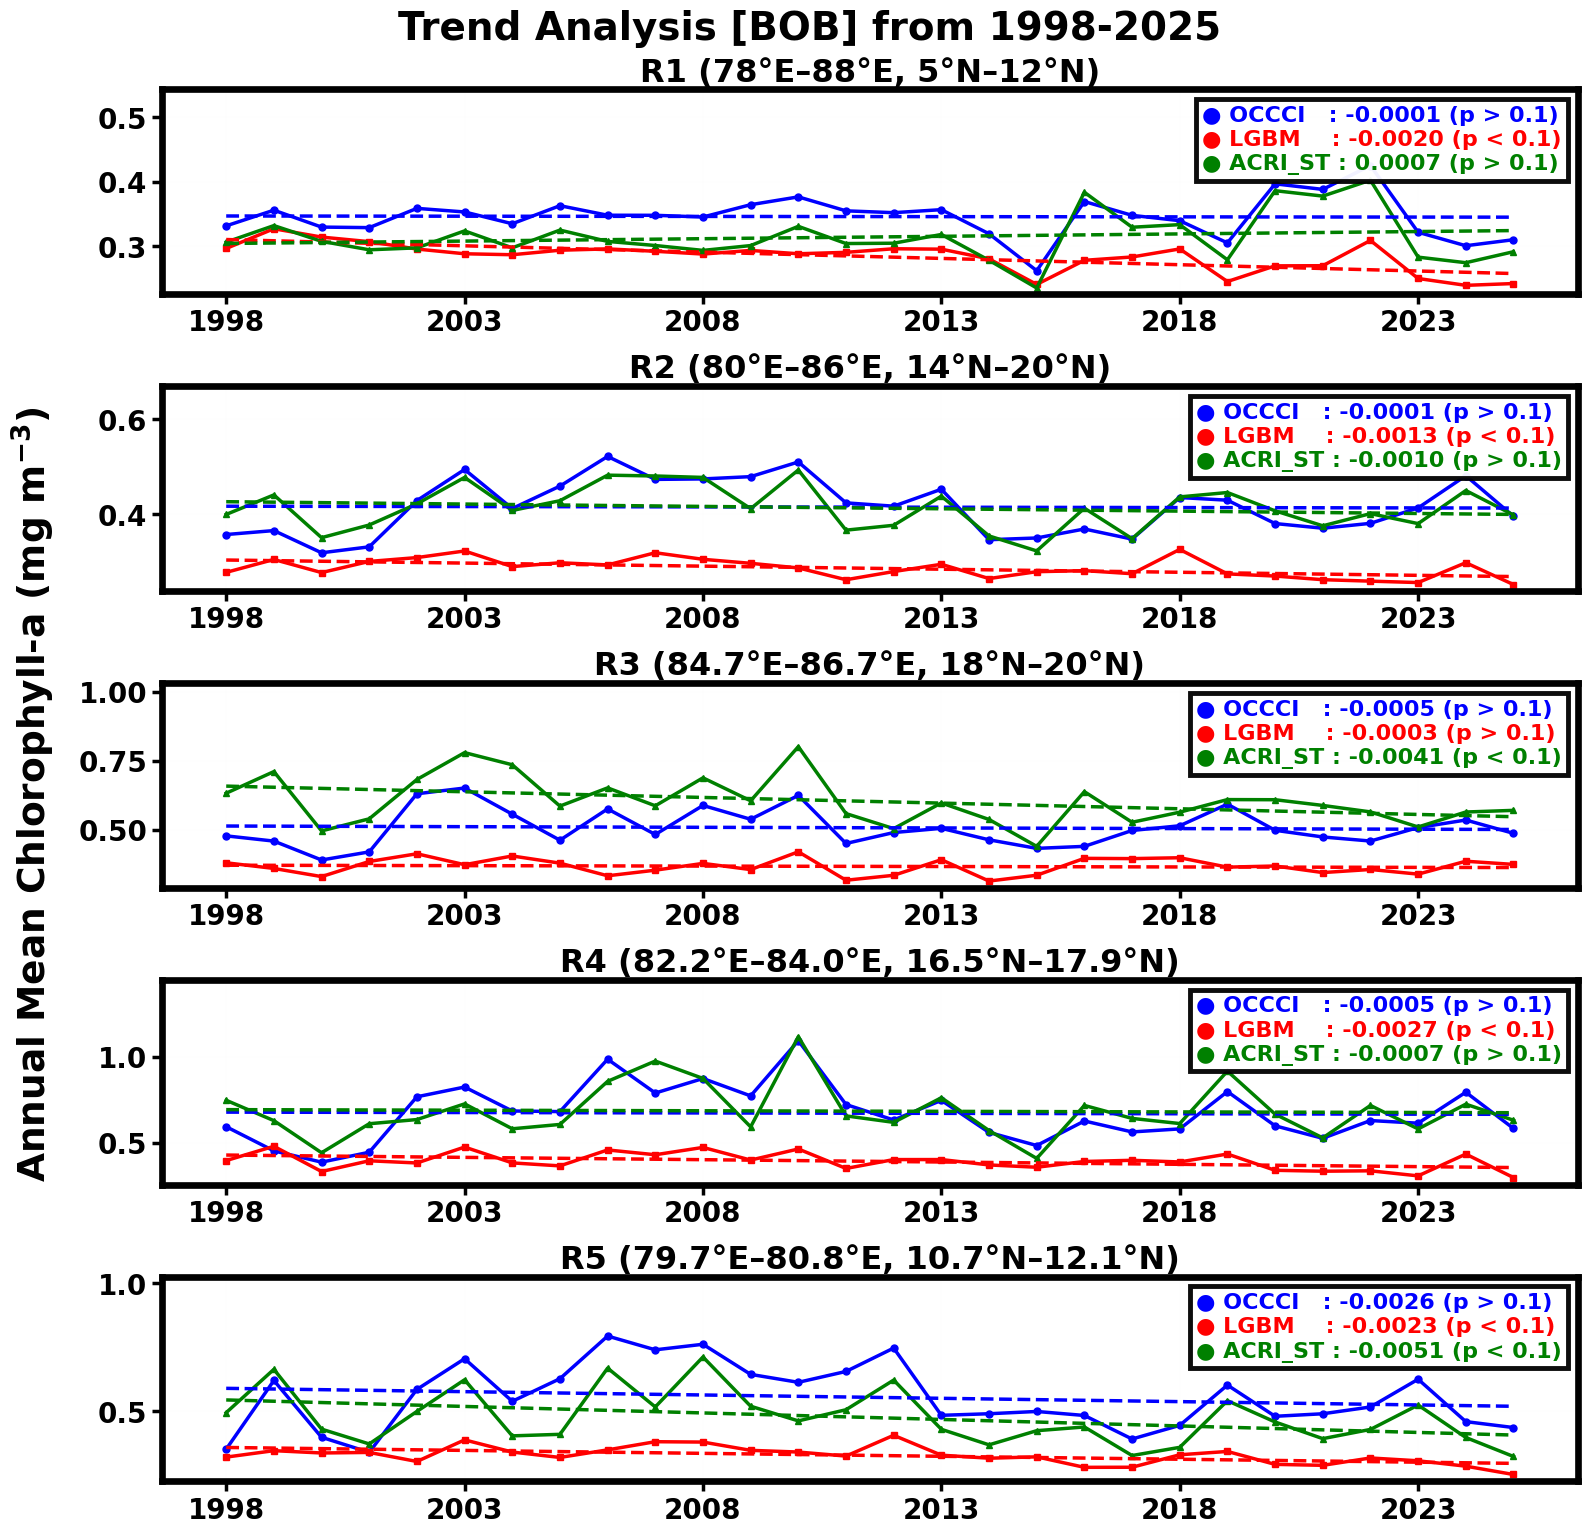

In [13]:
# ==========================================================
# Annual Trend Analysis
# Observed vs LGBM Prediction
# BOB Subregions (1998–2025)
# ==========================================================

from matplotlib.offsetbox import TextArea, VPacker, AnchoredOffsetbox




# ==========================================================
# Subregions (BOB)
# ==========================================================

regions = {
    "R1 (78°E–88°E, 5°N–12°N)":  [78.0, 88.0, 5.0, 12.0],
    "R2 (80°E–86°E, 14°N–20°N)": [80.0, 86.0, 14.0, 20.0],
    "R3 (84.7°E–86.7°E, 18°N–20°N)": [84.7, 86.7, 18.0, 20.0],
    "R4 (82.2°E–84.0°E, 16.5°N–17.9°N)": [82.2, 84.0, 16.5, 17.9],
    "R5 (79.7°E–80.8°E, 10.7°N–12.1°N)": [79.7, 80.8, 10.7, 12.1],
}


# ==========================================================
# Global Style
# ==========================================================

plt.rcParams["font.weight"] = "bold"
plt.rcParams["axes.labelweight"] = "bold"
plt.rcParams["axes.titleweight"] = "bold"



# ==========================================================
# Figure
# ==========================================================

fig = plt.figure(figsize=(16.0, 16.0))

gs = fig.add_gridspec(
    nrows=5,
    ncols=1,
    height_ratios=[1.25]*5,
    hspace=0.45
)

plot_axes = []

for i in range(5):
    plot_axes.append(
        fig.add_subplot(gs[i])
    )




# ==========================================================
# P-value formatting
# ==========================================================

def format_p(p):
    return "p < 0.1" if p < 0.1 else "p > 0.1"
    
    
      
    
# ==========================================================
# Loop over regions
# ==========================================================

stats_list = []
for ax, (region_name, box) in zip(plot_axes, regions.items()):

    lon1, lon2, lat1, lat2 = box

    # ------------------------------------------------------
    # Subset
    # ------------------------------------------------------

    obs = ds_occci["chlor_a"].sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )

    pred = ds_lgbm["chlor_a_pred"].sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )
    
    gap = ds_gapfree["CHL"].sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )

    # ------------------------------------------------------
    # Spatial Mean
    # ------------------------------------------------------

    obs = obs.mean(
        dim=("latitude","longitude"),
        skipna=True
    )

    pred = pred.mean(
        dim=("latitude","longitude"),
        skipna=True
    )
    
    gap = gap.mean(
        dim=("latitude","longitude"),
        skipna=True
    )

    # ------------------------------------------------------
    # Annual Mean
    # ------------------------------------------------------

    # Annual means
    obs_year = obs.groupby("time.year").mean()
    pred_year = pred.groupby("time.year").mean()
    gap_year = gap.groupby("time.year").mean()

    # Convert to pandas Series
    obs_series = obs_year.to_series()
    pred_series = pred_year.to_series()
    gap_series = gap_year.to_series()

    # Keep only common years
    annual = (
        obs_series.to_frame("Observed")
        .join(pred_series.to_frame("LGBM"), how="inner")
        .join(gap_series.to_frame("GapFree"), how="inner")
    )

    years = annual.index.values

    obs_values = annual["Observed"].values
    pred_values = annual["LGBM"].values
    gap_values  = annual["GapFree"].values

    # ------------------------------------------------------
    # Linear Regression
    # ------------------------------------------------------

    obs_fit = linregress(
        years,
        obs_values
    )

    pred_fit = linregress(
        years,
        pred_values
    )
    
    gap_fit = linregress(
        years,
        gap_values
    )
    
    obs_p_txt  = format_p(obs_fit.pvalue)
    pred_p_txt = format_p(pred_fit.pvalue)
    gap_p_txt  = format_p(gap_fit.pvalue)
    
    

    stats_list.append(
        (
            obs_fit.slope,
            obs_fit.pvalue,
            pred_fit.slope,
            pred_fit.pvalue,
            gap_fit.slope,
            gap_fit.pvalue
        )
    )
    obs_trend = (
        obs_fit.intercept
        + obs_fit.slope * years
    )

    pred_trend = (
        pred_fit.intercept
        + pred_fit.slope * years
    )
    gap_trend = (
        gap_fit.intercept
        + gap_fit.slope * years
    )

    # ------------------------------------------------------
    # Annual Mean Points
    # ------------------------------------------------------

    ax.plot(
        years,
        obs_values,
        color="blue",
        marker="o",
        linestyle="-",
        linewidth=2.5,
        markersize=5,
        label="OCCCI"
    )

    ax.plot(
        years,
        pred_values,
        color="red",
        marker="s",
        linestyle="-",
        linewidth=2.5,
        markersize=5,
        label="LGBM"
    )
    
    ax.plot(
        years,
        gap_values,
        color="green",
        marker="^",
        linestyle="-",
        linewidth=2.5,
        markersize=5,
        label="ACRI_ST"
    )

    # ------------------------------------------------------
    # Trend Lines
    # ------------------------------------------------------

    ax.plot(
        years,
        obs_trend,
        "--",
        color="blue",
        linewidth=2.5,
        label="OCCCI Trend"
    )

    ax.plot(
        years,
        pred_trend,
        "--",
        color="red",
        linewidth=2.5,
        label="LGBM Trend"
    )
    ax.plot(
        years,
        gap_trend,
        "--",
        color="green",
        linewidth=2.5,
        label="ACRI_ST Trend"
    )

    

    # ------------------------------------------------------
    # Cosmetics
    # ------------------------------------------------------

    ax.set_title(
        region_name,
        fontsize=23,
        fontweight="bold"
    )

    ax.grid(
        linestyle="--",
        linewidth=0.02,
        alpha=0.30
    )

    ax.set_xticks(
        np.arange(1998,2026,5)
    )

    ax.tick_params(
        axis="both",
        which="major",
        labelsize=20,
        width=2.5,
        length=7
    )

    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold")

    for tick in ax.get_yticklabels():
        tick.set_fontweight("bold")
        
    # Bold subplot borders
    for spine in ax.spines.values():
        spine.set_linewidth(4.8)
        
    ymin, ymax = ax.get_ylim()
    ax.set_ylim(ymin, ymax * 1.25)    
    
    # ------------------------------------------------------
    # Statistics Box
    # ------------------------------------------------------

    obs_box = TextArea(
        f"● OCCCI   : {obs_fit.slope:.4f} ({obs_p_txt})",
        textprops=dict(
            color="blue",
            fontsize=16,
            fontweight="bold"
        )
    )

    pred_box = TextArea(
        f"● LGBM    : {pred_fit.slope:.4f} ({pred_p_txt})",
        textprops=dict(
            color="red",
            fontsize=16,
            fontweight="bold"
        )
    )

    gap_box = TextArea(
        f"● ACRI_ST : {gap_fit.slope:.4f} ({gap_p_txt})",
        textprops=dict(
            color="green",
            fontsize=16,
            fontweight="bold"
        )
    )

    stats_box = VPacker(
        children=[obs_box, pred_box, gap_box],
        align="left",
        pad=0,
        sep=3
    )

    anchored_box = AnchoredOffsetbox(
        loc="upper right",
        child=stats_box,
        frameon=True,
        borderpad=0.7,
        pad=0.45
    )

    anchored_box.patch.set_facecolor("white")
    anchored_box.patch.set_edgecolor("black")
    anchored_box.patch.set_linewidth(3.5)
    anchored_box.patch.set_alpha(0.95)

    ax.add_artist(anchored_box)
    
    

    
    
    
# ==========================================================
# Common Labels
# ==========================================================

fig.text(
    0.5,
    0.095,
    "",
    ha="center",
    va="center",
    fontsize=17,
    fontweight="bold"
)

fig.text(
    0.0001,
    0.5,
    "Annual Mean Chlorophyll-a (mg m$^{-3}$)",
    va="center",
    rotation="vertical",
    fontsize=27,
    fontweight="bold"
)




# ==========================================================
# Figure Title
# ==========================================================

plt.suptitle(
    "Trend Analysis [BOB] from 1998-2025",
    fontsize=28,
    fontweight="bold",
    x= 0.50,
    y=0.99
)

# ==========================================================
# Layout
# ==========================================================

plt.subplots_adjust(
    top=0.94,
    bottom=0.07,
    left=0.095,
    right=0.98,
    hspace=0.65,
    wspace=0.15
)






plt.show()




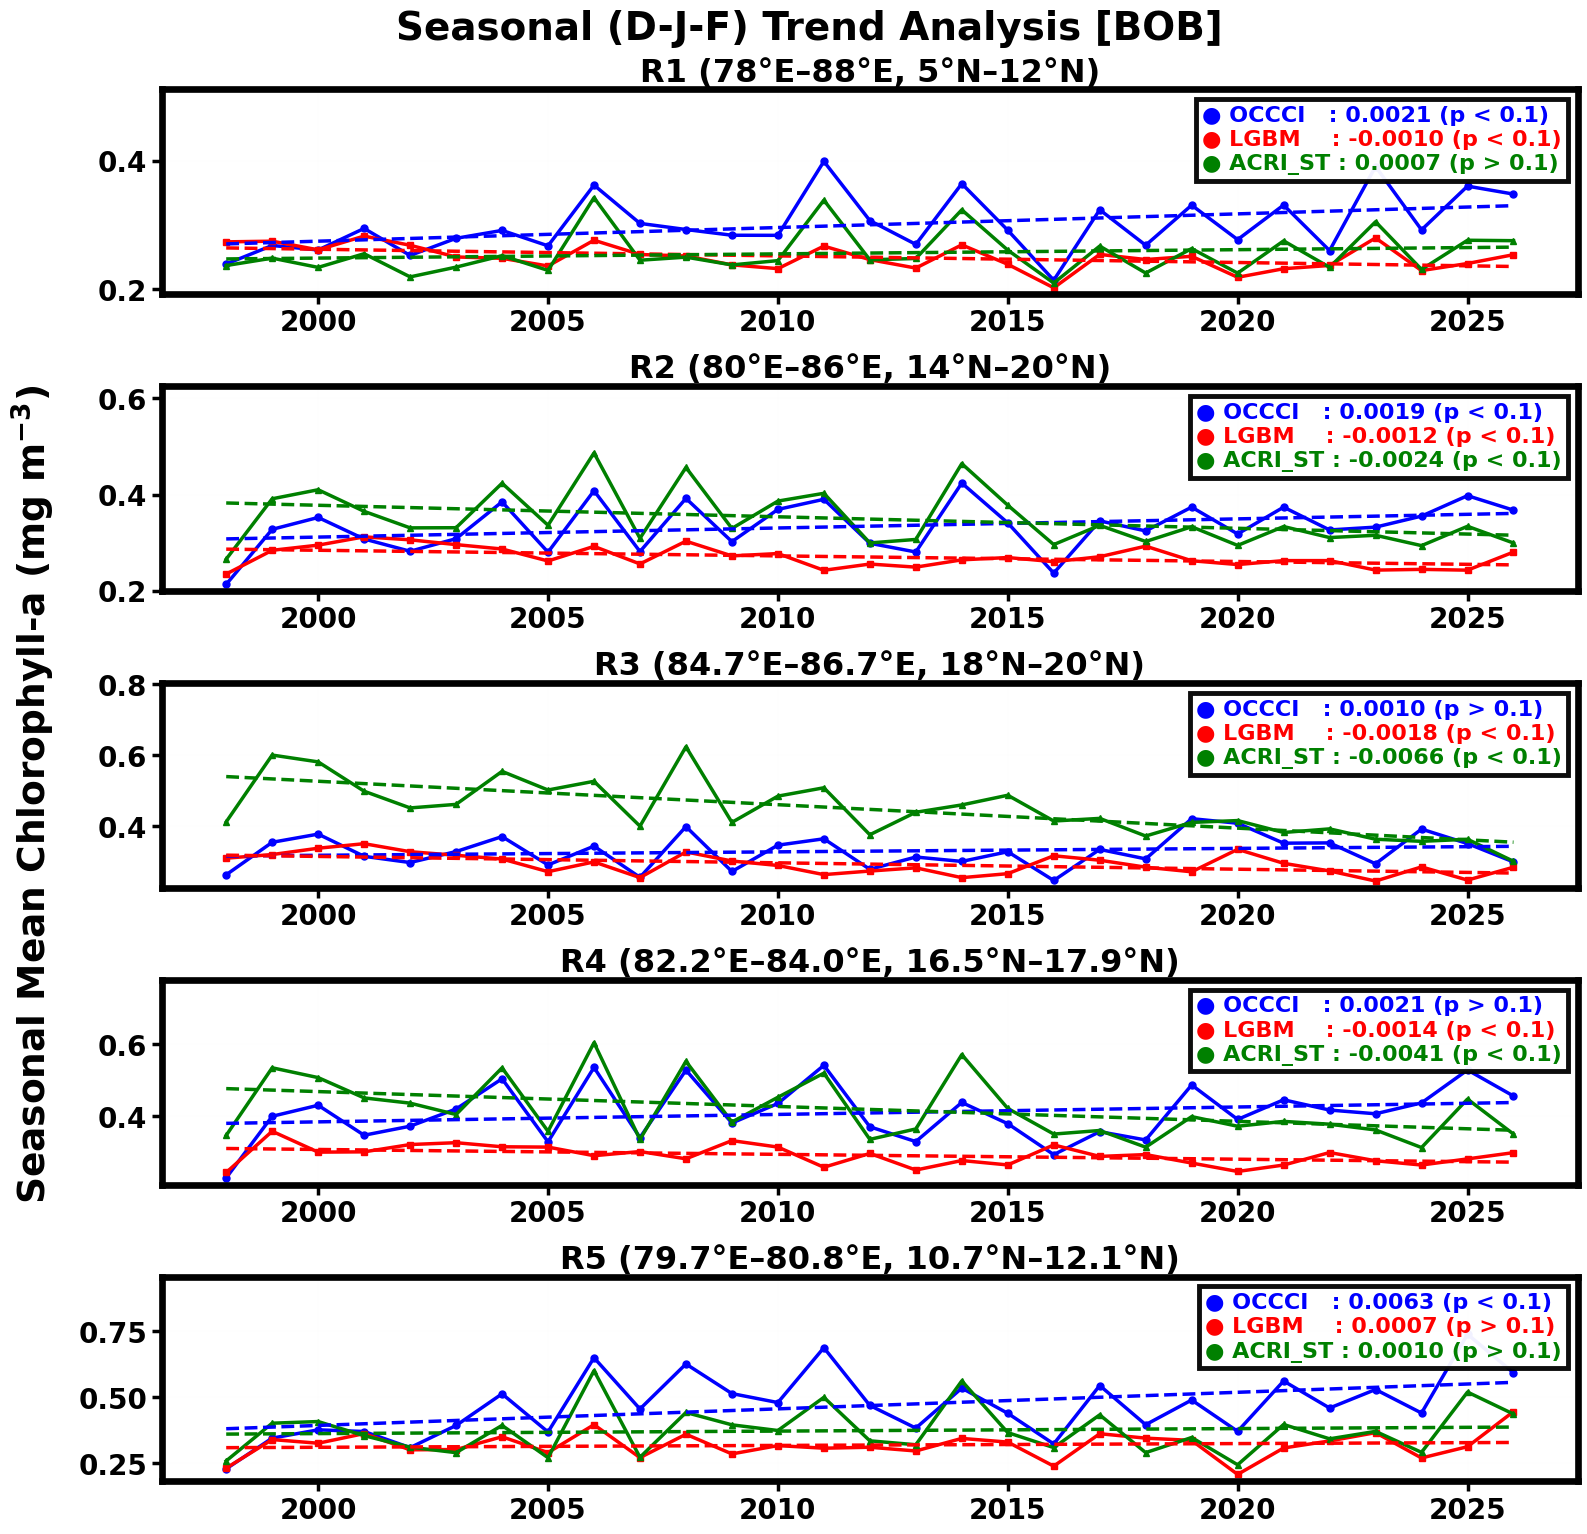

In [14]:
# ==========================================================
# Annual Trend Analysis
# Observed vs LGBM Prediction
# BOB Subregions (1998–2025)
# ==========================================================

from matplotlib.offsetbox import TextArea, VPacker, AnchoredOffsetbox




# ==========================================================
# Subregions (BOB)
# ==========================================================

regions = {
    "R1 (78°E–88°E, 5°N–12°N)":  [78.0, 88.0, 5.0, 12.0],
    "R2 (80°E–86°E, 14°N–20°N)": [80.0, 86.0, 14.0, 20.0],
    "R3 (84.7°E–86.7°E, 18°N–20°N)": [84.7, 86.7, 18.0, 20.0],
    "R4 (82.2°E–84.0°E, 16.5°N–17.9°N)": [82.2, 84.0, 16.5, 17.9],
    "R5 (79.7°E–80.8°E, 10.7°N–12.1°N)": [79.7, 80.8, 10.7, 12.1],
}


# ==========================================================
# Global Style
# ==========================================================

plt.rcParams["font.weight"] = "bold"
plt.rcParams["axes.labelweight"] = "bold"
plt.rcParams["axes.titleweight"] = "bold"



# ==========================================================
# Figure
# ==========================================================

fig = plt.figure(figsize=(16.0, 16.0))

gs = fig.add_gridspec(
    nrows=5,
    ncols=1,
    height_ratios=[1.25]*5,
    hspace=0.45
)

plot_axes = []

for i in range(5):
    plot_axes.append(
        fig.add_subplot(gs[i])
    )




# ==========================================================
# P-value formatting
# ==========================================================

def format_p(p):
    return "p < 0.1" if p < 0.1 else "p > 0.1"
    
    
      
    
# ==========================================================
# Loop over regions
# ==========================================================

stats_list = []
for ax, (region_name, box) in zip(plot_axes, regions.items()):

    lon1, lon2, lat1, lat2 = box

    # ------------------------------------------------------
    # Subset
    # ------------------------------------------------------

    obs = ds_occci["chlor_a"].sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )

    pred = ds_lgbm["chlor_a_pred"].sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )
    
    gap = ds_gapfree["CHL"].sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )

    # ------------------------------------------------------
    # Spatial Mean
    # ------------------------------------------------------

    obs = obs.mean(
        dim=("latitude","longitude"),
        skipna=True
    )

    pred = pred.mean(
        dim=("latitude","longitude"),
        skipna=True
    )
    
    gap = gap.mean(
        dim=("latitude","longitude"),
        skipna=True
    )

    # ------------------------------------------------------
    # DJF Seasonal Mean
    # ------------------------------------------------------

    def seasonal_mean_DJF(da):

        # Keep only December, January and February
        da = da.where(da.time.dt.season == "DJF", drop=True)

        # Assign December to the following year's season
        season_year = xr.where(
            da.time.dt.month == 12,
            da.time.dt.year + 1,
            da.time.dt.year
        )

        da = da.assign_coords(
            season_year=("time", season_year.data)
        )

        # Average each DJF season
        return da.groupby("season_year").mean()

    obs_year  = seasonal_mean_DJF(obs)
    pred_year = seasonal_mean_DJF(pred)
    gap_year  = seasonal_mean_DJF(gap)

    # Convert to pandas Series
    obs_series = obs_year.to_series()
    pred_series = pred_year.to_series()
    gap_series = gap_year.to_series()

    # Keep only common years
    annual = (
        obs_series.to_frame("Observed")
        .join(pred_series.to_frame("LGBM"), how="inner")
        .join(gap_series.to_frame("GapFree"), how="inner")
    )

    years = annual.index.values

    obs_values = annual["Observed"].values
    pred_values = annual["LGBM"].values
    gap_values  = annual["GapFree"].values

    # ------------------------------------------------------
    # Linear Regression
    # ------------------------------------------------------

    obs_fit = linregress(
        years,
        obs_values
    )

    pred_fit = linregress(
        years,
        pred_values
    )
    
    gap_fit = linregress(
        years,
        gap_values
    )
    
    obs_p_txt  = format_p(obs_fit.pvalue)
    pred_p_txt = format_p(pred_fit.pvalue)
    gap_p_txt  = format_p(gap_fit.pvalue)
    
    

    stats_list.append(
        (
            obs_fit.slope,
            obs_fit.pvalue,
            pred_fit.slope,
            pred_fit.pvalue,
            gap_fit.slope,
            gap_fit.pvalue
        )
    )
    obs_trend = (
        obs_fit.intercept
        + obs_fit.slope * years
    )

    pred_trend = (
        pred_fit.intercept
        + pred_fit.slope * years
    )
    gap_trend = (
        gap_fit.intercept
        + gap_fit.slope * years
    )

    # ------------------------------------------------------
    # Annual Mean Points
    # ------------------------------------------------------

    ax.plot(
        years,
        obs_values,
        color="blue",
        marker="o",
        linestyle="-",
        linewidth=2.5,
        markersize=5,
        label="OCCCI"
    )

    ax.plot(
        years,
        pred_values,
        color="red",
        marker="s",
        linestyle="-",
        linewidth=2.5,
        markersize=5,
        label="LGBM"
    )
    
    ax.plot(
        years,
        gap_values,
        color="green",
        marker="^",
        linestyle="-",
        linewidth=2.5,
        markersize=5,
        label="ACRI_ST"
    )

    # ------------------------------------------------------
    # Trend Lines
    # ------------------------------------------------------

    ax.plot(
        years,
        obs_trend,
        "--",
        color="blue",
        linewidth=2.5,
        label="OCCCI Trend"
    )

    ax.plot(
        years,
        pred_trend,
        "--",
        color="red",
        linewidth=2.5,
        label="LGBM Trend"
    )
    ax.plot(
        years,
        gap_trend,
        "--",
        color="green",
        linewidth=2.5,
        label="ACRI_ST Trend"
    )

    

    # ------------------------------------------------------
    # Cosmetics
    # ------------------------------------------------------

    ax.set_title(
        region_name,
        fontsize=23,
        fontweight="bold"
    )

    ax.grid(
        linestyle="--",
        linewidth=0.02,
        alpha=0.30
    )

    ax.set_xticks(
        np.arange(2000,2026,5)
    )

    ax.tick_params(
        axis="both",
        which="major",
        labelsize=20,
        width=2.5,
        length=7
    )

    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold")

    for tick in ax.get_yticklabels():
        tick.set_fontweight("bold")
        
    # Bold subplot borders
    for spine in ax.spines.values():
        spine.set_linewidth(4.8)
        
    ymin, ymax = ax.get_ylim()
    ax.set_ylim(ymin, ymax * 1.25)    
    
    # ------------------------------------------------------
    # Statistics Box
    # ------------------------------------------------------

    obs_box = TextArea(
        f"● OCCCI   : {obs_fit.slope:.4f} ({obs_p_txt})",
        textprops=dict(
            color="blue",
            fontsize=16,
            fontweight="bold"
        )
    )

    pred_box = TextArea(
        f"● LGBM    : {pred_fit.slope:.4f} ({pred_p_txt})",
        textprops=dict(
            color="red",
            fontsize=16,
            fontweight="bold"
        )
    )

    gap_box = TextArea(
        f"● ACRI_ST : {gap_fit.slope:.4f} ({gap_p_txt})",
        textprops=dict(
            color="green",
            fontsize=16,
            fontweight="bold"
        )
    )

    stats_box = VPacker(
        children=[obs_box, pred_box, gap_box],
        align="left",
        pad=0,
        sep=3
    )

    anchored_box = AnchoredOffsetbox(
        loc="upper right",
        child=stats_box,
        frameon=True,
        borderpad=0.7,
        pad=0.45
    )

    anchored_box.patch.set_facecolor("white")
    anchored_box.patch.set_edgecolor("black")
    anchored_box.patch.set_linewidth(3.5)
    anchored_box.patch.set_alpha(0.95)

    ax.add_artist(anchored_box)
    
    

    
    
    
# ==========================================================
# Common Labels
# ==========================================================

fig.text(
    0.5,
    0.095,
    "",
    ha="center",
    va="center",
    fontsize=17,
    fontweight="bold"
)

fig.text(
    0.0001,
    0.5,
    "Seasonal Mean Chlorophyll-a (mg m$^{-3}$)",
    va="center",
    rotation="vertical",
    fontsize=27,
    fontweight="bold"
)




# ==========================================================
# Figure Title
# ==========================================================

plt.suptitle(
    "Seasonal (D-J-F) Trend Analysis [BOB]",
    fontsize=28,
    fontweight="bold",
    x= 0.50,
    y=0.99
)

# ==========================================================
# Layout
# ==========================================================

plt.subplots_adjust(
    top=0.94,
    bottom=0.07,
    left=0.095,
    right=0.98,
    hspace=0.65,
    wspace=0.15
)






plt.show()




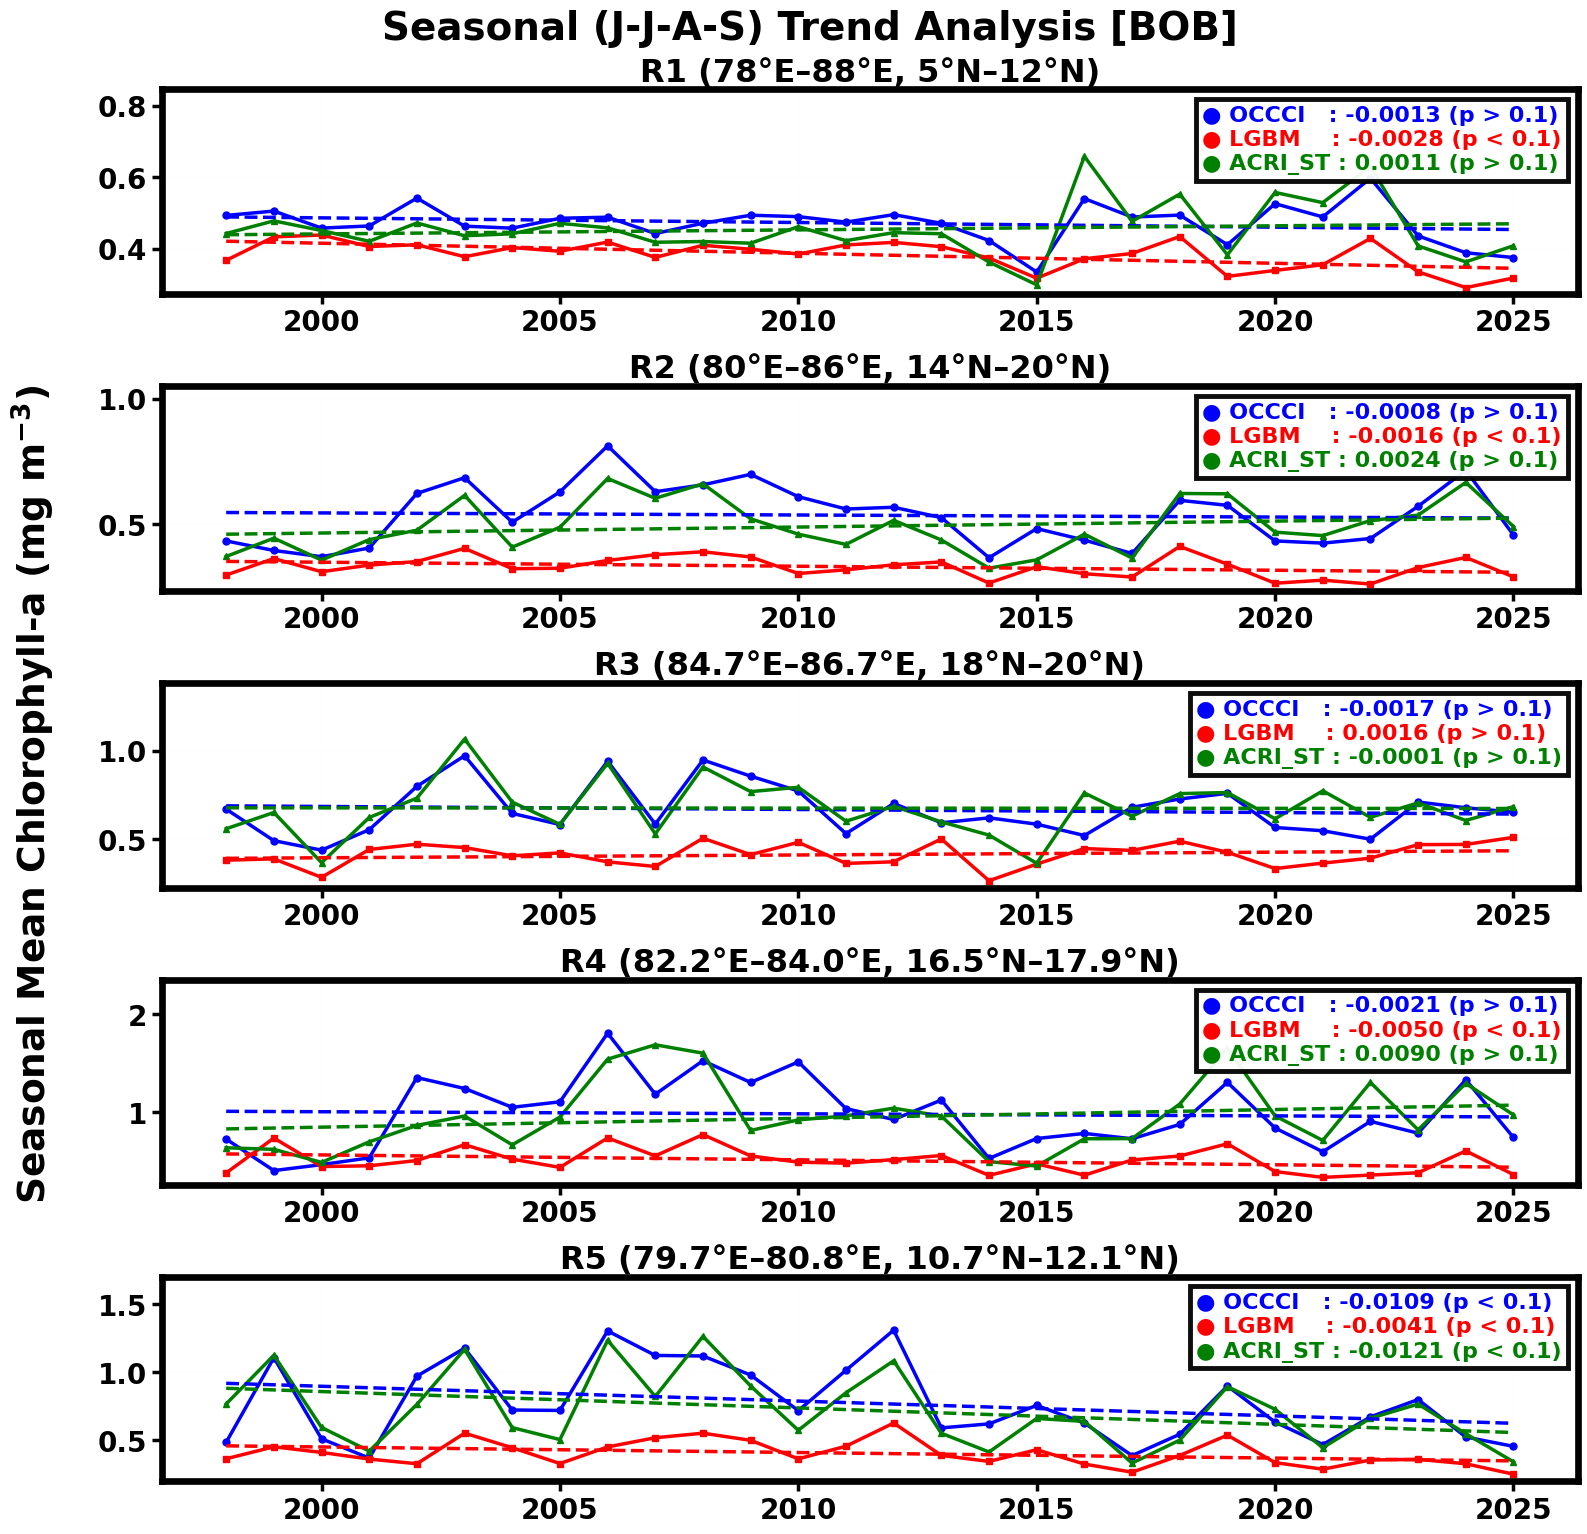

In [15]:
# ==========================================================
# Annual Trend Analysis
# Observed vs LGBM Prediction
# BOB Subregions (1998–2025)
# ==========================================================

from matplotlib.offsetbox import TextArea, VPacker, AnchoredOffsetbox




# ==========================================================
# Subregions (BOB)
# ==========================================================

regions = {
    "R1 (78°E–88°E, 5°N–12°N)":  [78.0, 88.0, 5.0, 12.0],
    "R2 (80°E–86°E, 14°N–20°N)": [80.0, 86.0, 14.0, 20.0],
    "R3 (84.7°E–86.7°E, 18°N–20°N)": [84.7, 86.7, 18.0, 20.0],
    "R4 (82.2°E–84.0°E, 16.5°N–17.9°N)": [82.2, 84.0, 16.5, 17.9],
    "R5 (79.7°E–80.8°E, 10.7°N–12.1°N)": [79.7, 80.8, 10.7, 12.1],
}


# ==========================================================
# Global Style
# ==========================================================

plt.rcParams["font.weight"] = "bold"
plt.rcParams["axes.labelweight"] = "bold"
plt.rcParams["axes.titleweight"] = "bold"



# ==========================================================
# Figure
# ==========================================================

fig = plt.figure(figsize=(16.0, 16.0))

gs = fig.add_gridspec(
    nrows=5,
    ncols=1,
    height_ratios=[1.25]*5,
    hspace=0.45
)

plot_axes = []

for i in range(5):
    plot_axes.append(
        fig.add_subplot(gs[i])
    )




# ==========================================================
# P-value formatting
# ==========================================================

def format_p(p):
    return "p < 0.1" if p < 0.1 else "p > 0.1"
    
    
      
    
# ==========================================================
# Loop over regions
# ==========================================================

stats_list = []
for ax, (region_name, box) in zip(plot_axes, regions.items()):

    lon1, lon2, lat1, lat2 = box

    # ------------------------------------------------------
    # Subset
    # ------------------------------------------------------

    obs = ds_occci["chlor_a"].sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )

    pred = ds_lgbm["chlor_a_pred"].sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )
    
    gap = ds_gapfree["CHL"].sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )

    # ------------------------------------------------------
    # Spatial Mean
    # ------------------------------------------------------

    obs = obs.mean(
        dim=("latitude","longitude"),
        skipna=True
    )

    pred = pred.mean(
        dim=("latitude","longitude"),
        skipna=True
    )
    
    gap = gap.mean(
        dim=("latitude","longitude"),
        skipna=True
    )

    # ------------------------------------------------------
    # JJAS Seasonal Mean
    # ------------------------------------------------------

    def seasonal_mean_JJAS(da):

        # Keep only June, July, August and September
        da = da.where(da.time.dt.month.isin([6, 7, 8, 9]), drop=True)

        # Average JJAS for each calendar year
        return da.groupby("time.year").mean()

    obs_year  = seasonal_mean_JJAS(obs)
    pred_year = seasonal_mean_JJAS(pred)
    gap_year  = seasonal_mean_JJAS(gap)

    # Convert to pandas Series
    obs_series = obs_year.to_series()
    pred_series = pred_year.to_series()
    gap_series = gap_year.to_series()

    # Keep only common years
    annual = (
        obs_series.to_frame("Observed")
        .join(pred_series.to_frame("LGBM"), how="inner")
        .join(gap_series.to_frame("GapFree"), how="inner")
    )

    years = annual.index.values

    obs_values = annual["Observed"].values
    pred_values = annual["LGBM"].values
    gap_values  = annual["GapFree"].values

    # ------------------------------------------------------
    # Linear Regression
    # ------------------------------------------------------

    obs_fit = linregress(
        years,
        obs_values
    )

    pred_fit = linregress(
        years,
        pred_values
    )
    
    gap_fit = linregress(
        years,
        gap_values
    )
    
    obs_p_txt  = format_p(obs_fit.pvalue)
    pred_p_txt = format_p(pred_fit.pvalue)
    gap_p_txt  = format_p(gap_fit.pvalue)
    
    

    stats_list.append(
        (
            obs_fit.slope,
            obs_fit.pvalue,
            pred_fit.slope,
            pred_fit.pvalue,
            gap_fit.slope,
            gap_fit.pvalue
        )
    )
    obs_trend = (
        obs_fit.intercept
        + obs_fit.slope * years
    )

    pred_trend = (
        pred_fit.intercept
        + pred_fit.slope * years
    )
    gap_trend = (
        gap_fit.intercept
        + gap_fit.slope * years
    )

    # ------------------------------------------------------
    # Annual Mean Points
    # ------------------------------------------------------

    ax.plot(
        years,
        obs_values,
        color="blue",
        marker="o",
        linestyle="-",
        linewidth=2.5,
        markersize=5,
        label="OCCCI"
    )

    ax.plot(
        years,
        pred_values,
        color="red",
        marker="s",
        linestyle="-",
        linewidth=2.5,
        markersize=5,
        label="LGBM"
    )
    
    ax.plot(
        years,
        gap_values,
        color="green",
        marker="^",
        linestyle="-",
        linewidth=2.5,
        markersize=5,
        label="ACRI_ST"
    )

    # ------------------------------------------------------
    # Trend Lines
    # ------------------------------------------------------

    ax.plot(
        years,
        obs_trend,
        "--",
        color="blue",
        linewidth=2.5,
        label="OCCCI Trend"
    )

    ax.plot(
        years,
        pred_trend,
        "--",
        color="red",
        linewidth=2.5,
        label="LGBM Trend"
    )
    ax.plot(
        years,
        gap_trend,
        "--",
        color="green",
        linewidth=2.5,
        label="ACRI_ST Trend"
    )

    

    # ------------------------------------------------------
    # Cosmetics
    # ------------------------------------------------------

    ax.set_title(
        region_name,
        fontsize=23,
        fontweight="bold"
    )

    ax.grid(
        linestyle="--",
        linewidth=0.02,
        alpha=0.30
    )

    ax.set_xticks(
        np.arange(2000,2026,5)
    )

    ax.tick_params(
        axis="both",
        which="major",
        labelsize=20,
        width=2.5,
        length=7
    )

    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold")

    for tick in ax.get_yticklabels():
        tick.set_fontweight("bold")
        
    # Bold subplot borders
    for spine in ax.spines.values():
        spine.set_linewidth(4.8)
        
    ymin, ymax = ax.get_ylim()
    ax.set_ylim(ymin, ymax * 1.25)    
    
    # ------------------------------------------------------
    # Statistics Box
    # ------------------------------------------------------

    obs_box = TextArea(
        f"● OCCCI   : {obs_fit.slope:.4f} ({obs_p_txt})",
        textprops=dict(
            color="blue",
            fontsize=16,
            fontweight="bold"
        )
    )

    pred_box = TextArea(
        f"● LGBM    : {pred_fit.slope:.4f} ({pred_p_txt})",
        textprops=dict(
            color="red",
            fontsize=16,
            fontweight="bold"
        )
    )

    gap_box = TextArea(
        f"● ACRI_ST : {gap_fit.slope:.4f} ({gap_p_txt})",
        textprops=dict(
            color="green",
            fontsize=16,
            fontweight="bold"
        )
    )

    stats_box = VPacker(
        children=[obs_box, pred_box, gap_box],
        align="left",
        pad=0,
        sep=3
    )

    anchored_box = AnchoredOffsetbox(
        loc="upper right",
        child=stats_box,
        frameon=True,
        borderpad=0.7,
        pad=0.45
    )

    anchored_box.patch.set_facecolor("white")
    anchored_box.patch.set_edgecolor("black")
    anchored_box.patch.set_linewidth(3.5)
    anchored_box.patch.set_alpha(0.95)

    ax.add_artist(anchored_box)
    
    

    
    
    
# ==========================================================
# Common Labels
# ==========================================================

fig.text(
    0.5,
    0.095,
    "",
    ha="center",
    va="center",
    fontsize=17,
    fontweight="bold"
)

fig.text(
    0.0001,
    0.5,
    "Seasonal Mean Chlorophyll-a (mg m$^{-3}$)",
    va="center",
    rotation="vertical",
    fontsize=27,
    fontweight="bold"
)




# ==========================================================
# Figure Title
# ==========================================================

plt.suptitle(
    "Seasonal (J-J-A-S) Trend Analysis [BOB]",
    fontsize=28,
    fontweight="bold",
    x= 0.50,
    y=0.99
)

# ==========================================================
# Layout
# ==========================================================

plt.subplots_adjust(
    top=0.94,
    bottom=0.07,
    left=0.095,
    right=0.98,
    hspace=0.65,
    wspace=0.15
)






plt.show()


